ML_Project

In [16]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from collections import Counter
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.metrics import r2_score, mean_absolute_error

In [3]:
data =pd.read_csv("housing.csv")
data

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY
...,...,...,...,...,...,...,...,...,...,...
20635,-121.09,39.48,25.0,1665.0,374.0,845.0,330.0,1.5603,78100.0,INLAND
20636,-121.21,39.49,18.0,697.0,150.0,356.0,114.0,2.5568,77100.0,INLAND
20637,-121.22,39.43,17.0,2254.0,485.0,1007.0,433.0,1.7000,92300.0,INLAND
20638,-121.32,39.43,18.0,1860.0,409.0,741.0,349.0,1.8672,84700.0,INLAND


In [4]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB


In [5]:
data.describe()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


In [7]:
data.isna().sum()

longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64

In [8]:
data.dropna(inplace=True)

In [9]:
data.isna().sum()

longitude             0
latitude              0
housing_median_age    0
total_rooms           0
total_bedrooms        0
population            0
households            0
median_income         0
median_house_value    0
ocean_proximity       0
dtype: int64

In [26]:
data.duplicated().sum()

np.int64(0)

TRAINIG

In [27]:
x= data.drop(["median_house_value"],axis=1)
y=data["median_house_value"]

In [28]:
x_train, x_test, y_train, y_test=train_test_split(x,y, test_size=0.2)

In [29]:
train_data=x_train.join(y_train)
train_data

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,ocean_proximity,median_house_value
8586,-118.39,33.90,7.0,4314.0,725.0,1699.0,718.0,8.2037,<1H OCEAN,500001.0
14799,-117.11,32.58,12.0,1086.0,294.0,870.0,290.0,2.4213,NEAR OCEAN,132500.0
13237,-117.69,34.13,8.0,2915.0,371.0,1271.0,354.0,7.9627,INLAND,345400.0
11126,-117.91,33.85,22.0,1178.0,289.0,865.0,294.0,3.0250,<1H OCEAN,180000.0
129,-122.20,37.84,30.0,2211.0,346.0,844.0,343.0,6.0666,NEAR BAY,311500.0
...,...,...,...,...,...,...,...,...,...,...
5773,-118.27,34.15,14.0,1744.0,536.0,1494.0,531.0,3.2171,<1H OCEAN,230800.0
7622,-118.25,33.86,26.0,3022.0,476.0,1852.0,452.0,6.0531,<1H OCEAN,186400.0
3226,-119.65,36.32,11.0,1294.0,314.0,713.0,290.0,1.5433,INLAND,50400.0
15215,-117.10,33.00,5.0,15502.0,2613.0,7417.0,2358.0,5.9094,<1H OCEAN,261100.0


array([[<Axes: title={'center': 'longitude'}>,
        <Axes: title={'center': 'latitude'}>,
        <Axes: title={'center': 'housing_median_age'}>],
       [<Axes: title={'center': 'total_rooms'}>,
        <Axes: title={'center': 'total_bedrooms'}>,
        <Axes: title={'center': 'population'}>],
       [<Axes: title={'center': 'households'}>,
        <Axes: title={'center': 'median_income'}>,
        <Axes: title={'center': 'median_house_value'}>]], dtype=object)

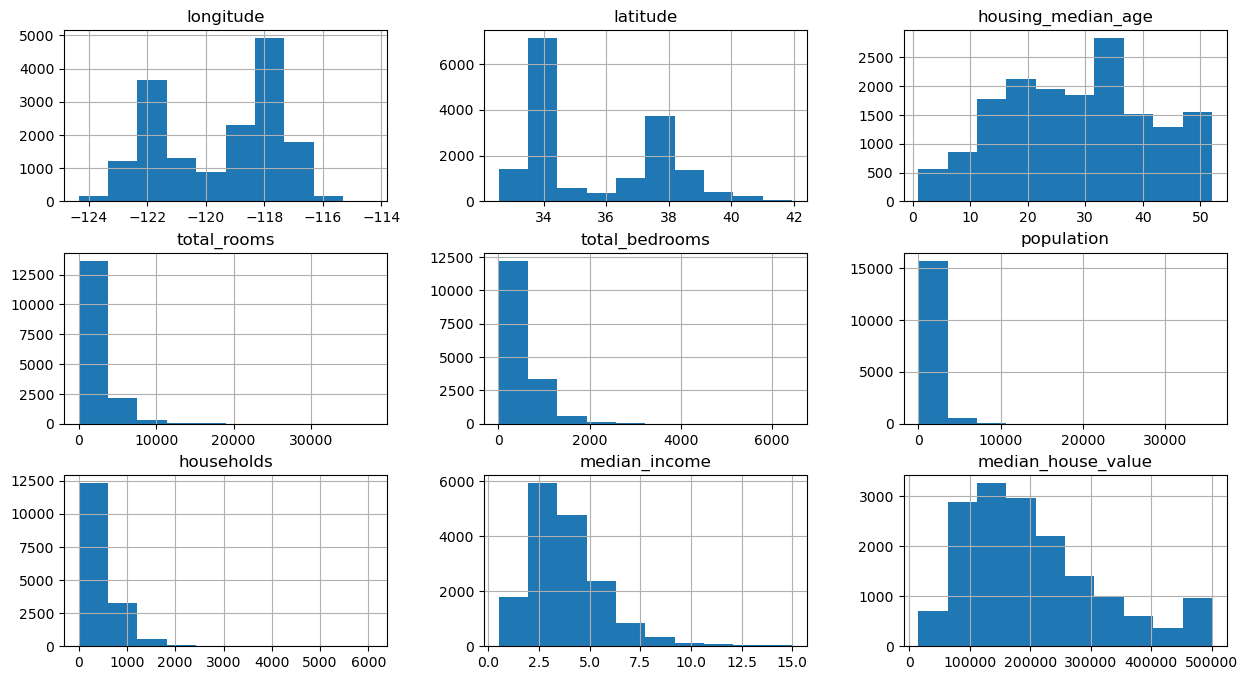

In [30]:
train_data.hist(figsize=(15,8))

<Axes: >

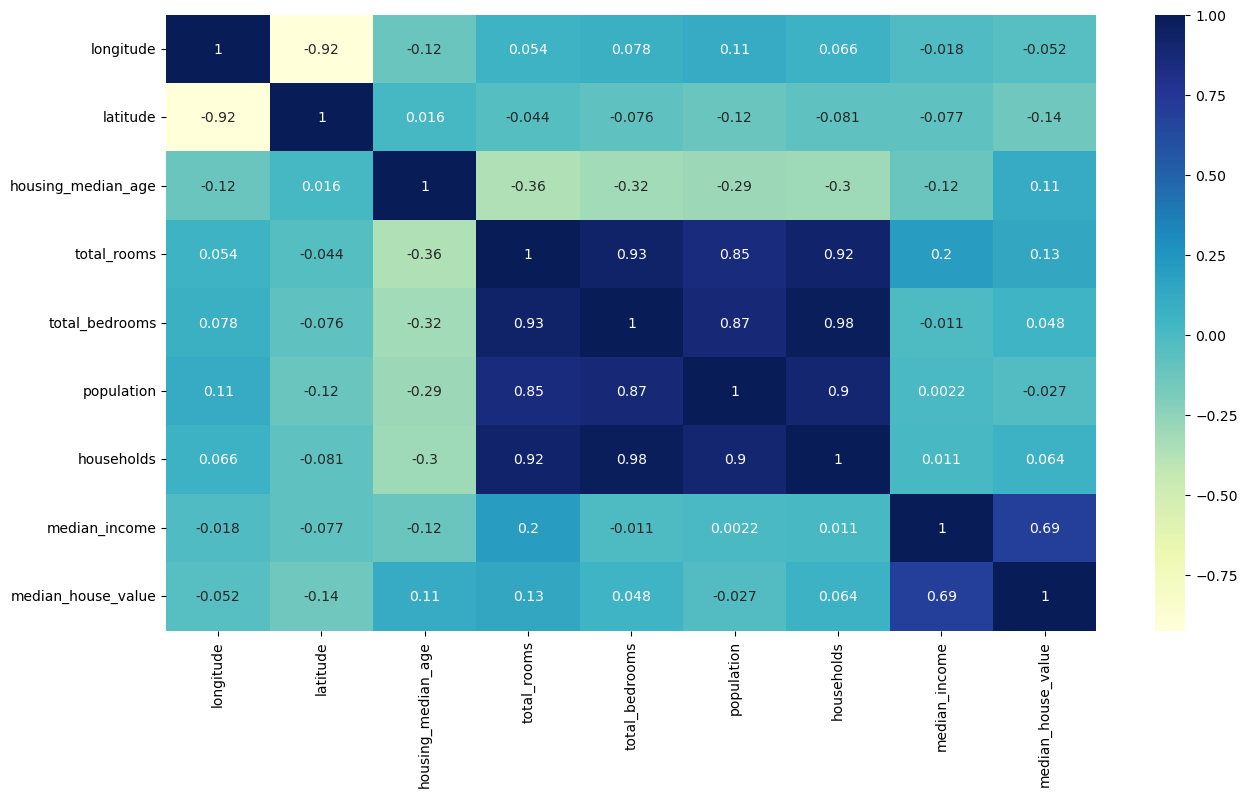

In [31]:
plt.figure(figsize=(15,8))
sns.heatmap(train_data.corr(numeric_only=True), annot=True, cmap="YlGnBu")

In [32]:
train_data["total_rooms"] = np.log(train_data["total_rooms"]+1)
train_data["total_bedrooms"] = np.log(train_data["total_bedrooms"]+1)
train_data["population"] = np.log(train_data["population"]+1)
train_data["households"] = np.log(train_data["households"]+1)

array([[<Axes: title={'center': 'longitude'}>,
        <Axes: title={'center': 'latitude'}>,
        <Axes: title={'center': 'housing_median_age'}>],
       [<Axes: title={'center': 'total_rooms'}>,
        <Axes: title={'center': 'total_bedrooms'}>,
        <Axes: title={'center': 'population'}>],
       [<Axes: title={'center': 'households'}>,
        <Axes: title={'center': 'median_income'}>,
        <Axes: title={'center': 'median_house_value'}>]], dtype=object)

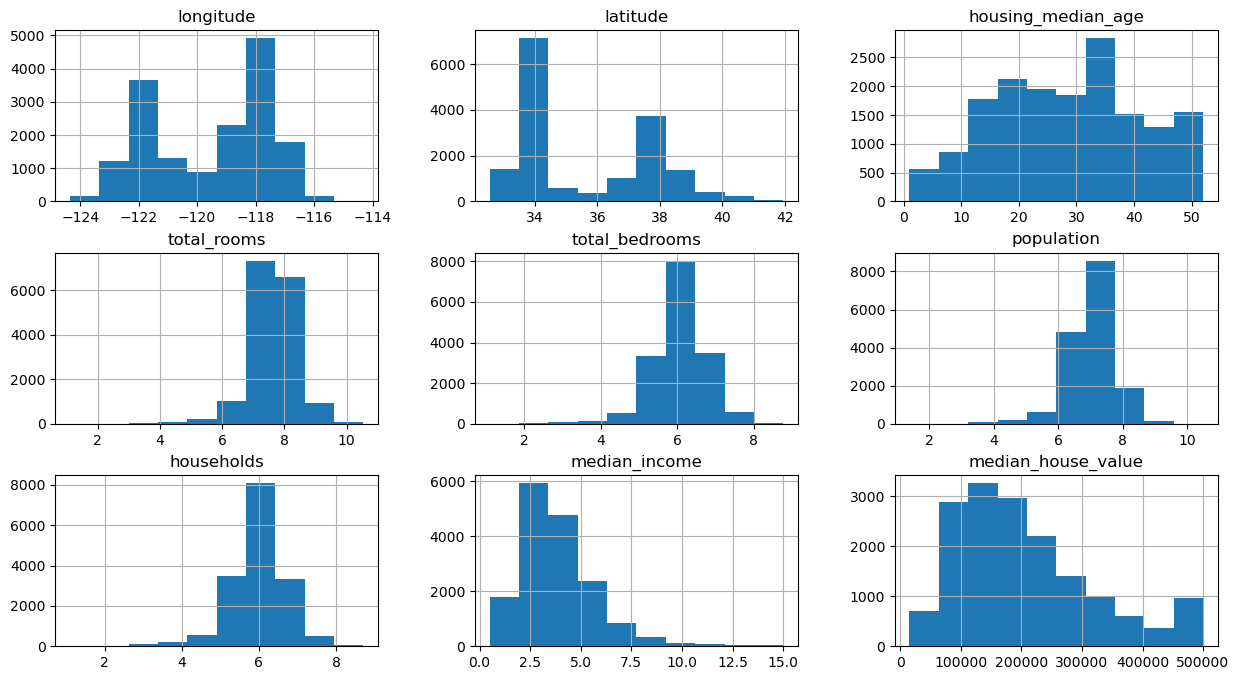

In [33]:
train_data.hist(figsize=(15,8))

In [34]:
train_data.ocean_proximity.value_counts()

ocean_proximity
<1H OCEAN     7207
INLAND        5187
NEAR OCEAN    2103
NEAR BAY      1845
ISLAND           4
Name: count, dtype: int64

In [35]:
train_data=train_data.join(pd.get_dummies(train_data.ocean_proximity)).drop(["ocean_proximity"],axis=1)

In [36]:
train_data

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,<1H OCEAN,INLAND,ISLAND,NEAR BAY,NEAR OCEAN
8586,-118.39,33.90,7.0,8.369853,6.587550,7.438384,6.577861,8.2037,500001.0,True,False,False,False,False
14799,-117.11,32.58,12.0,6.991177,5.686975,6.769642,5.673323,2.4213,132500.0,False,False,False,False,True
13237,-117.69,34.13,8.0,7.977968,5.918894,7.148346,5.872118,7.9627,345400.0,False,True,False,False,False
11126,-117.91,33.85,22.0,7.072422,5.669881,6.763885,5.686975,3.0250,180000.0,True,False,False,False,False
129,-122.20,37.84,30.0,7.701652,5.849325,6.739337,5.840642,6.0666,311500.0,False,False,False,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5773,-118.27,34.15,14.0,7.464510,6.285998,7.309881,6.276643,3.2171,230800.0,True,False,False,False,False
7622,-118.25,33.86,26.0,8.014005,6.167516,7.524561,6.115892,6.0531,186400.0,True,False,False,False,False
3226,-119.65,36.32,11.0,7.166266,5.752573,6.570883,5.673323,1.5433,50400.0,False,True,False,False,False
15215,-117.10,33.00,5.0,9.648789,7.868637,8.911665,7.765993,5.9094,261100.0,True,False,False,False,False


<Axes: >

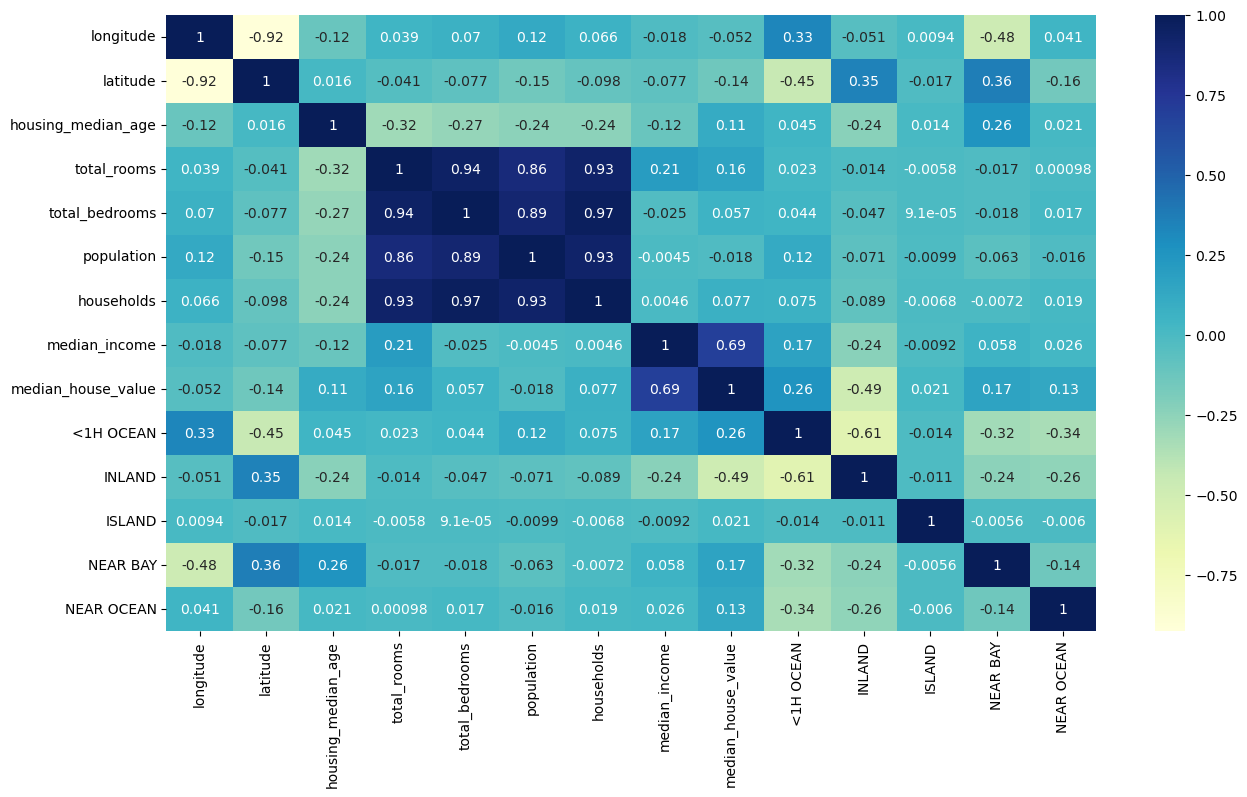

In [37]:
plt.figure(figsize=(15,8))
sns.heatmap(train_data.corr(numeric_only=True), annot=True, cmap="YlGnBu")

<Axes: xlabel='latitude', ylabel='longitude'>

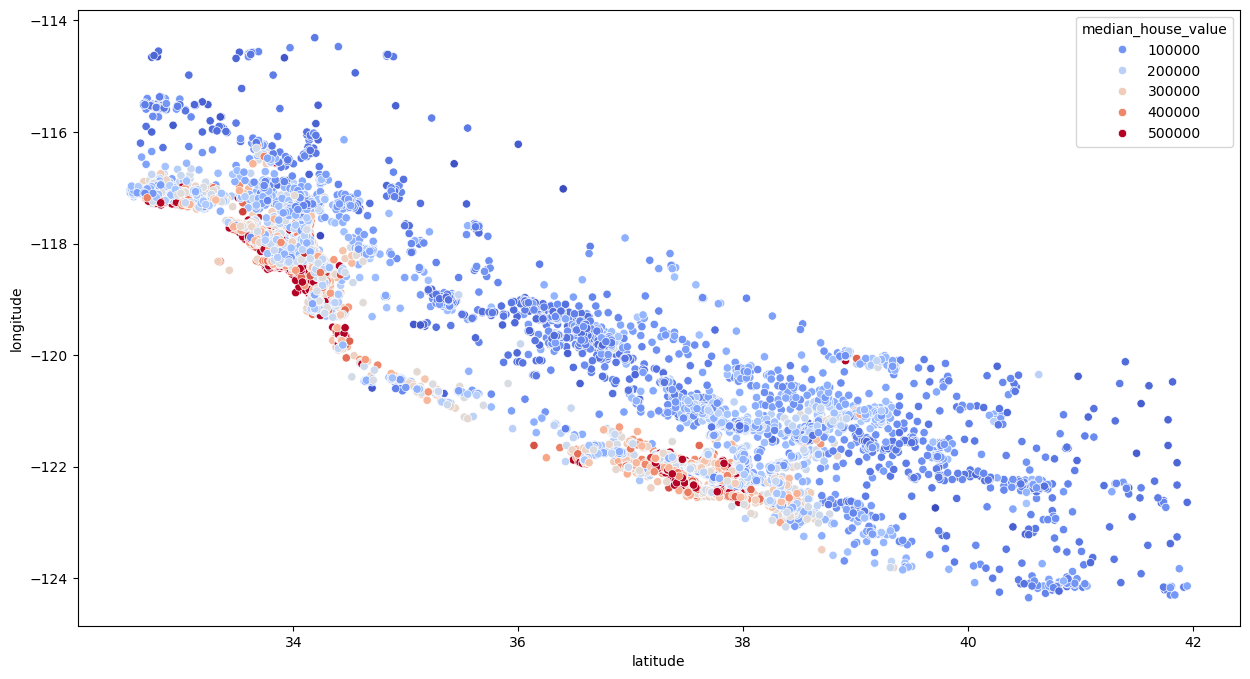

In [38]:
plt.figure(figsize=(15,8))
sns.scatterplot(x="latitude",y="longitude", data=train_data, hue="median_house_value", palette="coolwarm")

In [39]:
train_data["bedrooms_ratio"]=train_data["total_bedrooms"]/train_data["total_rooms"]
train_data["household_rooms"]=train_data["total_rooms"]/train_data["households"]

<Axes: >

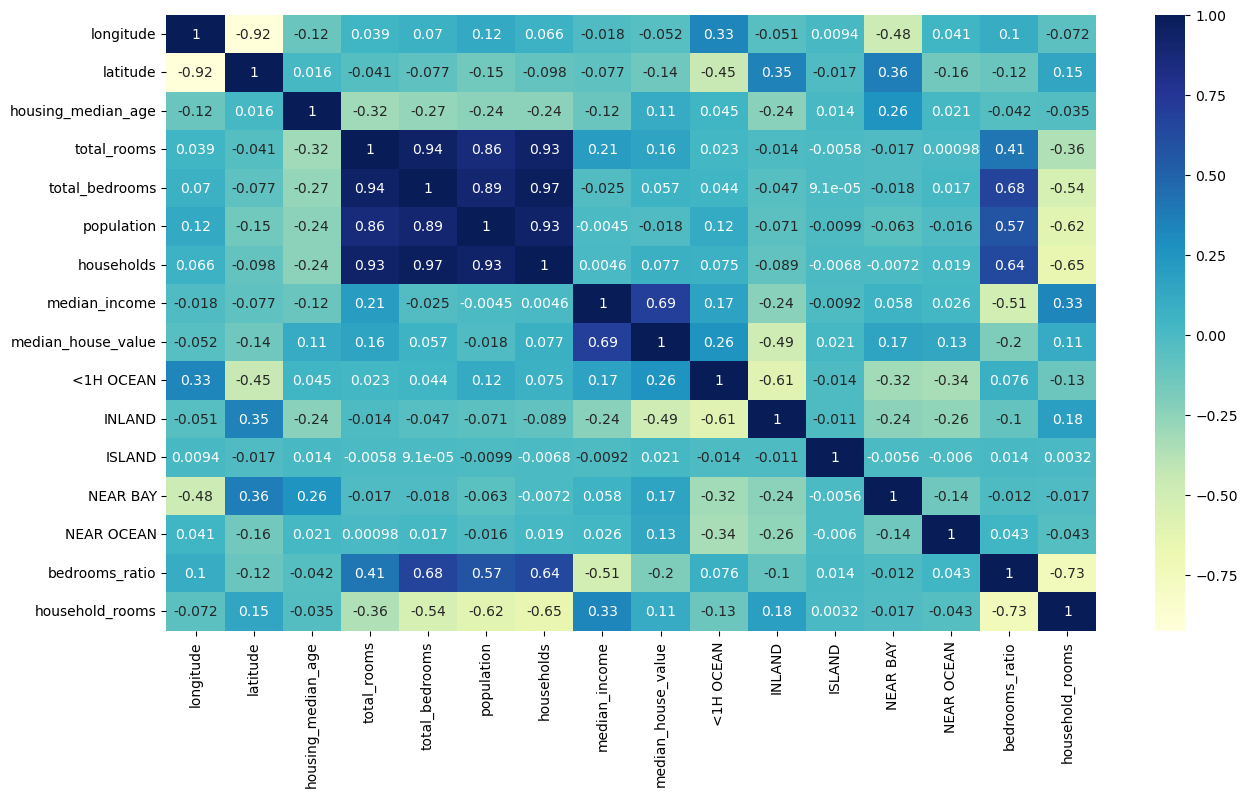

In [40]:
plt.figure(figsize=(15,8))
sns.heatmap(train_data.corr(numeric_only=True), annot=True, cmap="YlGnBu")

In [41]:
x_train, y_train= train_data.drop(["median_house_value"],axis=1) , train_data["median_house_value"]
reg= LinearRegression()
reg.fit(x_train, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [42]:
test_data=x_test.join(y_test)

test_data["total_rooms"] = np.log(test_data["total_rooms"]+1)
test_data["total_bedrooms"] = np.log(test_data["total_bedrooms"]+1)
test_data["population"] = np.log(test_data["population"]+1)
test_data["households"] = np.log(test_data["households"]+1)


test_data=test_data.join(pd.get_dummies(test_data.ocean_proximity)).drop(["ocean_proximity"],axis=1)


test_data["bedrooms_ratio"]=test_data["total_bedrooms"]/test_data["total_rooms"]
test_data["household_rooms"]=test_data["total_rooms"]/test_data["households"]

x_test, y_test= test_data.drop(["median_house_value"],axis=1) , test_data["median_house_value"]




In [43]:
test_data

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,<1H OCEAN,INLAND,ISLAND,NEAR BAY,NEAR OCEAN,bedrooms_ratio,household_rooms
9432,-122.81,38.08,19.0,7.387709,5.905362,6.704414,5.823046,3.4609,238800.0,False,False,False,False,True,0.799350,1.268702
13576,-117.30,34.14,37.0,7.282761,5.568345,6.635947,5.517453,2.3438,88100.0,False,True,False,False,False,0.764592,1.319950
5474,-118.46,33.99,44.0,7.023759,5.662960,6.276643,5.549076,4.0598,335900.0,True,False,False,False,False,0.806258,1.265753
18023,-121.95,37.25,34.0,7.974877,6.300786,7.156956,6.259581,5.5127,268200.0,True,False,False,False,False,0.790079,1.274027
13861,-117.27,34.50,8.0,8.179760,6.298949,7.033506,6.040255,5.3733,302600.0,False,True,False,False,False,0.770065,1.354208
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2743,-115.59,32.79,8.0,7.688913,5.730100,6.908755,5.662960,6.3814,159900.0,False,True,False,False,False,0.745242,1.357755
7279,-118.25,33.98,44.0,6.992096,5.817111,7.273786,5.739793,1.6667,112500.0,True,False,False,False,False,0.831955,1.218179
515,-122.24,37.83,52.0,7.471932,5.509388,6.373320,5.429346,5.8948,457800.0,False,False,False,True,False,0.737345,1.376212
17256,-119.70,34.42,43.0,7.497207,6.324359,7.307202,6.289716,2.6750,247900.0,True,False,False,False,False,0.843562,1.191979


In [44]:
reg.score(x_test,y_test)

0.6515761911817506

ExtraTreesRegressor

In [45]:
x = data.drop(columns=["median_house_value"]).copy()
y = data["median_house_value"].copy()

x = pd.get_dummies(
    x, columns=["ocean_proximity"], dtype=int
)

x["bedrooms_ratio"] = (
    x["total_bedrooms"] / x["total_rooms"].replace(0, np.nan)
)
x["rooms_per_household"] = (
    x["total_rooms"] / x["households"].replace(0, np.nan)
)
x["population_per_household"] = (
    x["population"] / x["households"].replace(0, np.nan)
)

valid = x.notna().all(axis=1) & y.notna()
x = x.loc[valid]
y = y.loc[valid]

In [46]:
x

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,ocean_proximity_<1H OCEAN,ocean_proximity_INLAND,ocean_proximity_ISLAND,ocean_proximity_NEAR BAY,ocean_proximity_NEAR OCEAN,bedrooms_ratio,rooms_per_household,population_per_household
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,0,0,0,1,0,0.146591,6.984127,2.555556
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,0,0,0,1,0,0.155797,6.238137,2.109842
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,0,0,0,1,0,0.129516,8.288136,2.802260
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,0,0,0,1,0,0.184458,5.817352,2.547945
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,0,0,0,1,0,0.172096,6.281853,2.181467
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
20635,-121.09,39.48,25.0,1665.0,374.0,845.0,330.0,1.5603,0,1,0,0,0,0.224625,5.045455,2.560606
20636,-121.21,39.49,18.0,697.0,150.0,356.0,114.0,2.5568,0,1,0,0,0,0.215208,6.114035,3.122807
20637,-121.22,39.43,17.0,2254.0,485.0,1007.0,433.0,1.7000,0,1,0,0,0,0.215173,5.205543,2.325635
20638,-121.32,39.43,18.0,1860.0,409.0,741.0,349.0,1.8672,0,1,0,0,0,0.219892,5.329513,2.123209


In [48]:

x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42
)

model = ExtraTreesRegressor(
    n_estimators=300,
    max_features=0.8,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

model.fit(x_train, y_train)

y_pred = model.predict(x_test)

print("R2 Score:", round(r2_score(y_test, y_pred), 4))
print("MAE:", round(mean_absolute_error(y_test, y_pred), 2))

R2 Score: 0.8173
MAE: 32569.8
